<a href="https://colab.research.google.com/github/Chithra679/AI-based-project/blob/main/Watermang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Sample water consumption data (litres per day)
data = {
    "Building": [
        "Engineering Block A",
        "Engineering Block B",
        "Hostel A",
        "Hostel B",
        "Library"
    ],
    "Expected_Usage": [5000, 4000, 6000, 5000, 2000],
    "Actual_Usage": [8000, 3500, 9000, 4800, 2200]
}

df = pd.DataFrame(data)

print("AquaGuard - Water Consumption Data")
print("----------------------------------")
display(df)

AquaGuard - Water Consumption Data
----------------------------------


,Building,Expected_Usage,Actual_Usage
0,Engineering Block A,5000,8000
1,Engineering Block B,4000,3500
2,Hostel A,6000,9000
3,Hostel B,5000,4800
4,Library,2000,2200


In [2]:
df["Excess_Usage"] = (
    df["Actual_Usage"] - df["Expected_Usage"]
)

print("Water Consumption Analysis")
display(df)

Water Consumption Analysis


,Building,Expected_Usage,Actual_Usage,Excess_Usage
0,Engineering Block A,5000,8000,3000
1,Engineering Block B,4000,3500,-500
2,Hostel A,6000,9000,3000
3,Hostel B,5000,4800,-200
4,Library,2000,2200,200


In [3]:
df["Usage_Status"] = "Normal"

high_usage = (
    df["Actual_Usage"] > df["Expected_Usage"] * 1.10
)

df.loc[high_usage, "Usage_Status"] = "High Usage"

print("AquaGuard - Usage Detection Results")
display(df)

AquaGuard - Usage Detection Results


,Building,Expected_Usage,Actual_Usage,Excess_Usage,Usage_Status
0,Engineering Block A,5000,8000,3000,High Usage
1,Engineering Block B,4000,3500,-500,Normal
2,Hostel A,6000,9000,3000,High Usage
3,Hostel B,5000,4800,-200,Normal
4,Library,2000,2200,200,Normal


In [4]:
print("AQUAGUARD ALERTS")
print("================")

alerts = df[df["Usage_Status"] == "High Usage"]

if alerts.empty:
    print("No unusually high water consumption detected.")

else:
    for _, row in alerts.iterrows():
        print(f"\nBuilding: {row['Building']}")
        print(f"Actual usage: {row['Actual_Usage']} litres/day")
        print(f"Expected usage: {row['Expected_Usage']} litres/day")
        print(f"Excess usage: {row['Excess_Usage']} litres/day")
        print("Action: Ask the maintenance team to investigate.")

AQUAGUARD ALERTS

Building: Engineering Block A
Actual usage: 8000 litres/day
Expected usage: 5000 litres/day
Excess usage: 3000 litres/day
Action: Ask the maintenance team to investigate.

Building: Hostel A
Actual usage: 9000 litres/day
Expected usage: 6000 litres/day
Excess usage: 3000 litres/day
Action: Ask the maintenance team to investigate.


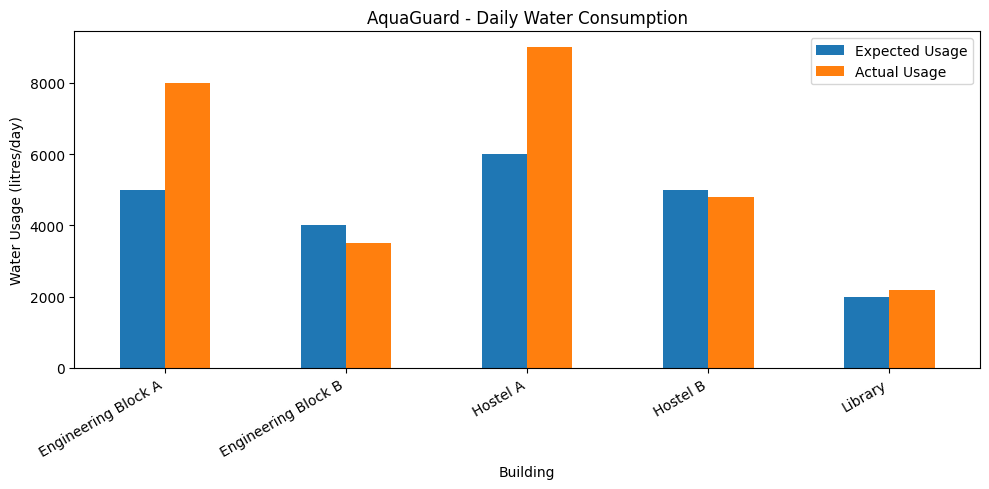

In [5]:
import matplotlib.pyplot as plt

df.plot(
    x="Building",
    y=["Expected_Usage", "Actual_Usage"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("AquaGuard - Daily Water Consumption")
plt.xlabel("Building")
plt.ylabel("Water Usage (litres/day)")
plt.xticks(rotation=30, ha="right")
plt.legend(["Expected Usage", "Actual Usage"])
plt.tight_layout()
plt.show()

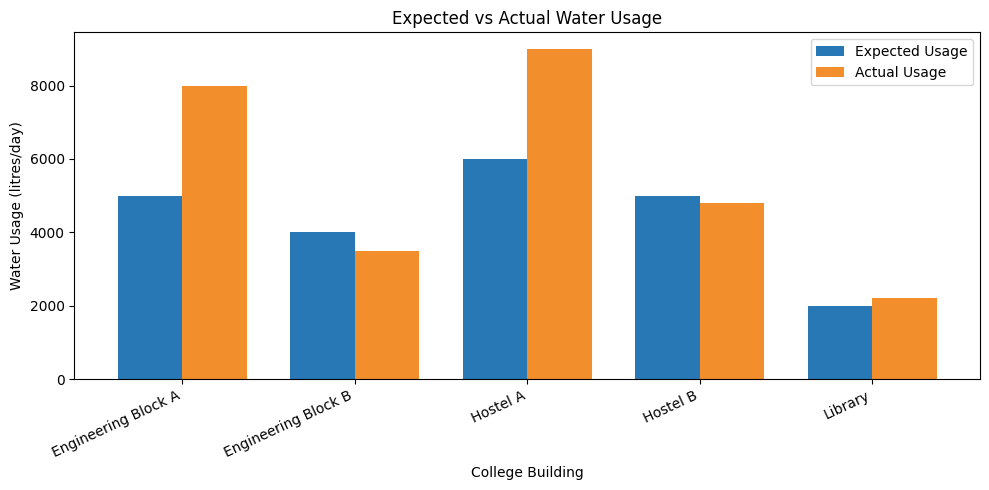

🚨 AQUAGUARD ALERTS


,Building,Expected_Usage,Actual_Usage,Excess_Usage,Usage_Status
0,Engineering Block A,5000,8000,3000,High Usage
2,Hostel A,6000,9000,3000,High Usage


Recommended action: Inspect flagged buildings and review usage.


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Dashboard heading
display(HTML("""
<div style="background:#123B52; color:white; padding:22px;
border-radius:12px; text-align:center;">
    <h1 style="margin:0;">💧 AquaGuard</h1>
    <p style="margin:8px 0 0;">
        Smart Water Consumption Monitoring System
    </p>
    <p style="margin:5px 0 0;">College Buildings & Hostels</p>
</div>
"""))

# Summary values
total_actual = df["Actual_Usage"].sum()
total_expected = df["Expected_Usage"].sum()
total_excess = max(0, total_actual - total_expected)
high_count = (df["Usage_Status"] == "High Usage").sum()

# Summary cards
display(HTML(f"""
<div style="display:flex; flex-wrap:wrap; gap:12px;
margin:16px 0;">
  <div style="background:#E8F4FD; padding:16px;
  border-radius:10px; flex:1; min-width:140px;">
    <b>Total Actual Usage</b>
    <h2 style="color:#1769AA;">{total_actual:,} L/day</h2>
  </div>
  <div style="background:#FFF2E5; padding:16px;
  border-radius:10px; flex:1; min-width:140px;">
    <b>Total Expected Usage</b>
    <h2 style="color:#C66A16;">{total_expected:,} L/day</h2>
  </div>
  <div style="background:#FDECEC; padding:16px;
  border-radius:10px; flex:1; min-width:140px;">
    <b>High-Usage Alerts</b>
    <h2 style="color:#B42318;">{high_count}</h2>
  </div>
</div>
"""))

# Building comparison chart
ax = df.plot(
    x="Building",
    y=["Expected_Usage", "Actual_Usage"],
    kind="bar",
    figsize=(10, 5),
    color=["#2878B5", "#F28E2B"],
    width=0.75
)

ax.set_title("Expected vs Actual Water Usage")
ax.set_xlabel("College Building")
ax.set_ylabel("Water Usage (litres/day)")
plt.xticks(rotation=25, ha="right")
plt.legend(["Expected Usage", "Actual Usage"])
plt.tight_layout()
plt.show()

# Alerts table
print("🚨 AQUAGUARD ALERTS")
alerts = df[df["Usage_Status"] == "High Usage"]

if alerts.empty:
    print("No unusually high usage detected.")
else:
    display(alerts[
        ["Building", "Expected_Usage",
         "Actual_Usage", "Excess_Usage", "Usage_Status"]
    ])

print("Recommended action: Inspect flagged buildings and review usage.")

In [8]:
from IPython.display import display, HTML

# Calculate excess usage
total_excess = (
    df["Actual_Usage"] - df["Expected_Usage"]
).clip(lower=0).sum()

alerts = df[df["Usage_Status"] == "High Usage"]

# Dashboard summary
display(HTML(f"""
<div style="background:#123B52; color:#FFFFFF;
padding:22px; border-radius:12px; font-family:Arial;">
    <h2 style="color:#FFFFFF;">💧 AquaGuard - Water Usage Report</h2>
    <p style="font-size:17px; color:#FFFFFF;">
        Total excess usage:
        <b style="color:#FFD166;">{total_excess:,} litres/day</b>
    </p>
    <p style="font-size:17px; color:#FFFFFF;">
        Buildings requiring investigation:
        <b style="color:#FFD166;">{len(alerts)}</b>
    </p>
</div>
"""))

# High-usage alert cards
if alerts.empty:
    display(HTML("""
    <div style="background:#123D2B; color:white;
    padding:20px; margin-top:12px; border-radius:10px;">
        <h3 style="color:#7CFFB2;">✅ All Clear</h3>
        <p>No unusually high water usage detected.</p>
    </div>
    """))
else:
    for _, row in alerts.iterrows():
        display(HTML(f"""
        <div style="background:#3A2025; color:#FFFFFF;
        border-left:7px solid #FF5252;
        padding:20px; margin-top:12px;
        border-radius:10px; font-family:Arial;">

            <h3 style="color:#FF7777;">
                ⚠️ HIGH USAGE: {row['Building']}
            </h3>

            <p style="color:#FFFFFF;">
                Expected usage:
                <b>{row['Expected_Usage']:,} litres/day</b>
            </p>

            <p style="color:#FFFFFF;">
                Actual usage:
                <b>{row['Actual_Usage']:,} litres/day</b>
            </p>

            <p style="color:#FFD166;">
                Excess usage:
                <b>{row['Excess_Usage']:,} litres/day</b>
            </p>

            <hr style="border-color:#80545A;">

            <p style="color:#FFFFFF;">
                <b>Recommended action:</b>
                Ask the maintenance team to investigate
                the unusually high consumption.
            </p>
        </div>
        """))

display(HTML("""
<div style="background:#202D3A; color:#D8E7F3;
padding:12px; margin-top:12px; border-radius:8px;">
    <b>Demo note:</b> This prototype uses sample data.
    High usage indicates a need to investigate; it does not
    automatically confirm a leak or water wastage.
</div>
"""))

In [9]:
from IPython.display import display, HTML

# Create a building-wise report
report = df.copy()

report["Usage_Percentage"] = (
    report["Actual_Usage"] /
    report["Expected_Usage"] * 100
).round(1)

report["Recommended_Action"] = report["Usage_Status"].map({
    "High Usage": "Investigate high consumption",
    "Normal": "Continue regular monitoring"
})

# Display report heading
display(HTML("""
<div style="background:#123B52; color:white;
padding:18px; border-radius:10px;">
    <h2 style="margin:0;">📊 Building-Wise Usage Report</h2>
    <p style="margin-bottom:0;">
        Daily water consumption analysis for college buildings
    </p>
</div>
"""))

# Display selected report columns
display(
    report[
        [
            "Building",
            "Expected_Usage",
            "Actual_Usage",
            "Usage_Percentage",
            "Usage_Status",
            "Recommended_Action"
        ]
    ].style.set_properties(**{
        "background-color": "#183044",
        "color": "white",
        "border-color": "#526779",
        "text-align": "left"
    }).set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#176B87"),
                ("color", "white"),
                ("font-weight", "bold")
            ]
        }
    ]).format({
        "Expected_Usage": "{:,.0f}",
        "Actual_Usage": "{:,.0f}",
        "Usage_Percentage": "{:.1f}%"
    })
)

print("\nNote: All values are sample data.")
print("Usage above the threshold requires investigation;")
print("it does not automatically confirm water wastage.")

,Building,Expected_Usage,Actual_Usage,Usage_Percentage,Usage_Status,Recommended_Action
0,Engineering Block A,"5,000","8,000",160.0%,High Usage,Investigate high consumption
1,Engineering Block B,"4,000","3,500",87.5%,Normal,Continue regular monitoring
2,Hostel A,"6,000","9,000",150.0%,High Usage,Investigate high consumption
3,Hostel B,"5,000","4,800",96.0%,Normal,Continue regular monitoring
4,Library,"2,000","2,200",110.0%,Normal,Continue regular monitoring



Note: All values are sample data.
Usage above the threshold requires investigation;
it does not automatically confirm water wastage.


In [10]:
from IPython.display import display, HTML

# Step 9: Water-saving recommendations

display(HTML("""
<div style="background:#123B52; color:white;
padding:20px; border-radius:12px; font-family:Arial;">
    <h2 style="margin:0;">💧 AquaGuard</h2>
    <h3 style="color:#7DE3D1;">
        Smart Water-Saving Recommendations
    </h3>
    <p>Practical actions based on building-wise water usage.</p>
</div>
"""))

for _, row in df.iterrows():

    building = row["Building"]
    expected = row["Expected_Usage"]
    actual = row["Actual_Usage"]
    status = row["Usage_Status"]
    excess = actual - expected

    if status == "High Usage":
        color = "#FF7777"
        background = "#3A2025"
        recommendation = (
            "Inspect taps and pipelines for possible leaks; "
            "check water tanks and review daily consumption."
        )
        priority = "HIGH PRIORITY"

    elif actual > expected:
        color = "#FFD166"
        background = "#35301D"
        recommendation = (
            "Monitor daily usage and check whether "
            "consumption can be reduced."
        )
        priority = "MONITOR"

    else:
        color = "#7CFFB2"
        background = "#183D30"
        recommendation = (
            "Continue regular monitoring and encourage "
            "responsible water use."
        )
        priority = "NORMAL"

    display(HTML(f"""
    <div style="background:{background}; color:#FFFFFF;
    border-left:6px solid {color}; padding:16px;
    margin-top:12px; border-radius:10px; font-family:Arial;">

        <h3 style="color:{color}; margin-top:0;">
            {building}
        </h3>

        <p>
            Expected: <b>{expected:,} litres/day</b><br>
            Actual: <b>{actual:,} litres/day</b><br>
            Difference: <b>{excess:+,} litres/day</b>
        </p>

        <p style="color:{color};">
            <b>{priority}</b>
        </p>

        <p>
            <b>Recommended action:</b><br>
            {recommendation}
        </p>
    </div>
    """))

print("Step 9 completed: Recommendations generated.")
print("Note: These recommendations use sample data.")
print("Inspections are needed to confirm the cause of high usage.")

Step 9 completed: Recommendations generated.
Note: These recommendations use sample data.
Inspections are needed to confirm the cause of high usage.


In [11]:
from IPython.display import display, HTML
import ipywidgets as widgets

# Step 10: Water-Saving Impact Calculator

# Calculate positive excess usage only
excess_by_building = (
    df["Actual_Usage"] - df["Expected_Usage"]
).clip(lower=0)

total_excess = excess_by_building.sum()

# Choose the target reduction percentage
reduction_slider = widgets.IntSlider(
    value=50,
    min=10,
    max=100,
    step=10,
    description="Reduction:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="70%")
)

def calculate_savings(reduction):
    estimated_saving = total_excess * reduction / 100
    remaining_excess = total_excess - estimated_saving

    display(HTML(f"""
    <div style="background:#123B52; color:white;
    padding:20px; border-radius:12px; font-family:Arial;">
        <h2>💧 AquaGuard - Impact Calculator</h2>
        <p>Total excess usage: <b>{total_excess:,} L/day</b></p>
        <p>Target reduction: <b>{reduction}%</b></p>
        <h2 style="color:#7CFFB2;">
            Estimated saving: {estimated_saving:,.0f} L/day
        </h2>
        <p>Potential monthly saving (30 days):
        <b>{estimated_saving * 30:,.0f} litres</b></p>
        <p>Remaining excess usage:
        <b>{remaining_excess:,.0f} L/day</b></p>
        <hr>
        <p>Suggested action: Investigate high-usage buildings,
        repair confirmed leaks, and monitor consumption.</p>
        <small>These are estimates based on sample data,
        not measured savings.</small>
    </div>
    """))

output = widgets.interactive_output(
    calculate_savings,
    {"reduction": reduction_slider}
)

display(reduction_slider, output)

IntSlider(value=50, description='Reduction:', layout=Layout(width='70%'), min=10, step=10, style=SliderStyle(d…

Output()

In [12]:
from IPython.display import display, HTML
import pandas as pd

# Step 11: Prepare the downloadable report
download_report = df.copy()

# Add usage percentage
download_report["Usage_Percentage"] = (
    download_report["Actual_Usage"] /
    download_report["Expected_Usage"] * 100
).round(1)

# Add recommended action
download_report["Recommended_Action"] = (
    download_report["Usage_Status"].map({
        "High Usage": "Investigate unusually high consumption",
        "Normal": "Continue regular monitoring"
    })
)

# Select and rename report columns
download_report = download_report[[
    "Building",
    "Expected_Usage",
    "Actual_Usage",
    "Excess_Usage",
    "Usage_Percentage",
    "Usage_Status",
    "Recommended_Action"
]].rename(columns={
    "Building": "Building",
    "Expected_Usage": "Expected_Usage_Litres_Per_Day",
    "Actual_Usage": "Actual_Usage_Litres_Per_Day",
    "Excess_Usage": "Excess_Usage_Litres_Per_Day"
})

# Save the report as a CSV file
filename = "AquaGuard_Water_Usage_Report.csv"
download_report.to_csv(filename, index=False)

display(HTML("""
<div style="background:#123B52; color:white;
padding:20px; border-radius:12px; font-family:Arial;">
    <h2>📥 AquaGuard Report Export</h2>
    <p>Your building-wise water usage report is ready.</p>
    <p>Includes expected usage, actual usage, excess usage,
    percentage, status, and recommended actions.</p>
</div>
"""))

display(download_report)

# Download the CSV file to your computer
from google.colab import files
files.download(filename)

,Building,Expected_Usage_Litres_Per_Day,Actual_Usage_Litres_Per_Day,Excess_Usage_Litres_Per_Day,Usage_Percentage,Usage_Status,Recommended_Action
0,Engineering Block A,5000,8000,3000,160.0,High Usage,Investigate unusually high consumption
1,Engineering Block B,4000,3500,-500,87.5,Normal,Continue regular monitoring
2,Hostel A,6000,9000,3000,150.0,High Usage,Investigate unusually high consumption
3,Hostel B,5000,4800,-200,96.0,Normal,Continue regular monitoring
4,Library,2000,2200,200,110.0,Normal,Continue regular monitoring


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=download_report)

https://docs.google.com/spreadsheets/d/1XOMud-b3vQyFnrTLYcRJ5PNVgak05scsVo_WfNZIu7c/edit#gid=0


In [15]:
from IPython.display import display, HTML

# Step 12: Final Summary Dashboard

# Calculate project summary values
total_buildings = len(df)

total_actual = df["Actual_Usage"].sum()
total_expected = df["Expected_Usage"].sum()

total_excess = (
    df["Actual_Usage"] - df["Expected_Usage"]
).clip(lower=0).sum()

high_usage_count = (
    df["Usage_Status"] == "High Usage"
).sum()

# Use the current Step 10 slider value if available
reduction = reduction_slider.value if "reduction_slider" in globals() else 50

estimated_saving = total_excess * reduction / 100

# Display dashboard heading
display(HTML("""
<div style="background:#123B52; color:white;
padding:22px; border-radius:14px; font-family:Arial;">
    <h1 style="margin:0;">💧 AquaGuard</h1>
    <h3 style="color:#7DE3D1;">
        Smart Water Consumption Monitoring
    </h3>
    <p>Final Project Summary | College Buildings & Hostels</p>
</div>
"""))

# Display summary cards
cards = [
    ("Buildings Monitored", f"{total_buildings}", "#D9EFFF", "#164E78"),
    ("Actual Usage", f"{total_actual:,} L/day", "#DDF7EF", "#146B50"),
    ("Excess Usage", f"{total_excess:,} L/day", "#FFF0D6", "#8A4B08"),
    ("High-Usage Alerts", f"{high_usage_count}", "#FFE1E1", "#A61B1B"),
    ("Estimated Daily Saving", f"{estimated_saving:,.0f} L/day", "#E9E1FF", "#5735A0")
]

card_html = """
<div style="display:flex; flex-wrap:wrap; gap:12px;
margin-top:16px; font-family:Arial;">
"""

for title, value, background, color in cards:
    card_html += f"""
    <div style="background:{background}; color:{color};
    padding:18px; border-radius:12px; flex:1;
    min-width:160px;">
        <p style="margin:0; font-size:14px;">{title}</p>
        <h2 style="margin-bottom:0;">{value}</h2>
    </div>
    """

card_html += "</div>"

display(HTML(card_html))

# Display project workflow
display(HTML("""
<div style="background:#1D2D3D; color:white;
padding:20px; border-radius:12px; margin-top:16px;
font-family:Arial;">
    <h3 style="color:#7DE3D1;">How AquaGuard Works</h3>
    <p>1. Enter sample water consumption data.</p>
    <p>2. Compare expected and actual usage.</p>
    <p>3. Flag unusually high consumption.</p>
    <p>4. Recommend investigation and water-saving actions.</p>
    <p>5. Calculate potential savings and export a report.</p>
</div>
"""))

# Fix: Summary cards with clearly visible numbers

cards = [
    ("Buildings Monitored", f"{len(df)}", "#D9EFFF", "#164E78"),
    ("Actual Usage", f"{df['Actual_Usage'].sum():,} L/day", "#DDF7EF", "#146B50"),
    ("Excess Usage", f"{(df['Actual_Usage'] - df['Expected_Usage']).clip(lower=0).sum():,} L/day", "#FFF0D6", "#8A4B08"),
    ("High-Usage Alerts", f"{(df['Usage_Status'] == 'High Usage').sum()}", "#FFE1E1", "#A61B1B"),
    ("Estimated Daily Saving", f"{((df['Actual_Usage'] - df['Expected_Usage']).clip(lower=0).sum() * (reduction_slider.value if 'reduction_slider' in globals() else 50) / 100):,.0f} L/day", "#E9E1FF", "#5735A0")
]

card_html = """
<div style="display:flex; flex-wrap:wrap; gap:12px;
margin-top:16px; font-family:Arial;">
"""

for title, value, background, color in cards:
    card_html += f"""
    <div style="background:{background}; color:{color};
    padding:18px; border-radius:12px; flex:1;
    min-width:160px;">
        <p style="margin:0; font-size:14px; color:{color};">
            {title}
        </p>
        <h2 style="margin:10px 0 0; font-size:23px;
        color:{color};">{value}</h2>
    </div>
    """

card_html += "</div>"
display(HTML(card_html))

In [16]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import pandas as pd

# Step 13: Editable building water usage input

building_input = widgets.Text(
    description="Building:",
    placeholder="e.g. Science Block",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="350px")
)

expected_input = widgets.IntText(
    value=3000,
    description="Expected (L/day):",
    style={"description_width": "initial"}
)

actual_input = widgets.IntText(
    value=3500,
    description="Actual (L/day):",
    style={"description_width": "initial"}
)

add_button = widgets.Button(
    description="Add Building",
    button_style="success",
    icon="plus"
)

input_output = widgets.Output()

display(HTML("""
<div style="background:#123B52; color:white;
padding:18px; border-radius:12px; font-family:Arial;">
    <h2>💧 AquaGuard - Add Building Data</h2>
    <p>Enter daily water usage to add a building to the analysis.</p>
</div>
"""))

display(building_input, expected_input, actual_input, add_button, input_output)

def add_building_data(button):
    with input_output:
        clear_output(wait=True)

        name = building_input.value.strip()
        expected = expected_input.value
        actual = actual_input.value

        if not name:
            print("Please enter a building name.")
            return

        if expected <= 0 or actual < 0:
            print("Expected usage must be greater than 0, and actual usage cannot be negative.")
            return

        if name.casefold() in df["Building"].astype(str).str.casefold().values:
            print("This building already exists. Please use a different name.")
            return

        excess = actual - expected
        status = "High Usage" if actual > expected * 1.10 else "Normal"

        new_row = pd.DataFrame([{
            "Building": name,
            "Expected_Usage": expected,
            "Actual_Usage": actual,
            "Excess_Usage": excess,
            "Usage_Status": status
        }])

        df.loc[len(df)] = new_row.iloc[0]

        print("Building added successfully!")
        print(f"Building: {name}")
        print(f"Expected usage: {expected:,} litres/day")
        print(f"Actual usage: {actual:,} litres/day")
        print(f"Difference: {excess:+,} litres/day")
        print(f"Status: {status}")
        print("\nUpdated building data:")
        display(df)

add_button.on_click(add_building_data)

Text(value='', description='Building:', layout=Layout(width='350px'), placeholder='e.g. Science Block', style=…

IntText(value=3000, description='Expected (L/day):', style=DescriptionStyle(description_width='initial'))

IntText(value=3500, description='Actual (L/day):', style=DescriptionStyle(description_width='initial'))

Button(button_style='success', description='Add Building', icon='plus', style=ButtonStyle())

Output()

In [20]:
import pandas as pd
from IPython.display import display, HTML

test_data = pd.DataFrame({
    "Test_Case": ["Test A", "Test B", "Test C"],
    "Expected_Usage": [3000, 3000, 3000],
    "Actual_Usage": [2500, 3000, 3500]
})

test_data["Expected_Status"] = [
    "Normal",
    "Normal",
    "High Usage"
]

test_data["Detected_Status"] = test_data.apply(
    lambda row: (
        "High Usage"
        if row["Actual_Usage"] > row["Expected_Usage"] * 1.10
        else "Normal"
    ),
    axis=1
)

test_data["Test_Result"] = (
    test_data["Expected_Status"] ==
    test_data["Detected_Status"]
).map({True: "PASS", False: "FAIL"})

display(HTML("""
<div style="background:#123B52; color:white;
padding:18px; border-radius:12px;">
<h2>💧 AquaGuard - System Test Report</h2>
<p>Checking water-usage alert accuracy</p>
</div>
"""))

display(test_data)

passed = (test_data["Test_Result"] == "PASS").sum()
print(f"Tests passed: {passed}/{len(test_data)}")

if passed == len(test_data):
    print("SUCCESS: All alert tests passed!")
else:
    print("Some tests failed. Please check the results.")

,Test_Case,Expected_Usage,Actual_Usage,Expected_Status,Detected_Status,Test_Result
0,Test A,3000,2500,Normal,Normal,PASS
1,Test B,3000,3000,Normal,Normal,PASS
2,Test C,3000,3500,High Usage,High Usage,PASS


Tests passed: 3/3
SUCCESS: All alert tests passed!


In [21]:
import pandas as pd
from google.colab import files
from IPython.display import display, HTML

# Create a fresh report from the current building data
download_report = df.copy()

# Calculate report values
download_report["Excess_Usage"] = (
    download_report["Actual_Usage"]
    - download_report["Expected_Usage"]
)

download_report["Usage_Percentage"] = (
    download_report["Actual_Usage"]
    / download_report["Expected_Usage"] * 100
).round(1)

download_report["Usage_Status"] = (
    download_report["Actual_Usage"]
    > download_report["Expected_Usage"] * 1.10
).map({True: "High Usage", False: "Normal"})

download_report["Recommended_Action"] = (
    download_report["Usage_Status"]
    .map({
        "High Usage": "Investigate unusually high consumption",
        "Normal": "Continue regular monitoring"
    })
)

# Add a clear report heading
display(HTML("""
<div style="background:#123B52; color:white;
padding:18px; border-radius:12px;">
<h2>💧 AquaGuard - Excel Report</h2>
<p>Building-wise water consumption and alerts</p>
</div>
"""))

display(download_report)

# Export the report
file_name = "AquaGuard_Water_Usage_Report.xlsx"

download_report.to_excel(file_name, index=False)

print("Excel report created successfully!")
files.download(file_name)

,Building,Expected_Usage,Actual_Usage,Excess_Usage,Usage_Status,Usage_Percentage,Recommended_Action
0,Engineering Block A,5000,8000,3000,High Usage,160.0,Investigate unusually high consumption
1,Engineering Block B,4000,3500,-500,Normal,87.5,Continue regular monitoring
2,Hostel A,6000,9000,3000,High Usage,150.0,Investigate unusually high consumption
3,Hostel B,5000,4800,-200,Normal,96.0,Continue regular monitoring
4,Library,2000,2200,200,Normal,110.0,Continue regular monitoring
5,science block,3000,3500,500,High Usage,116.7,Investigate unusually high consumption
6,med block,2997,3503,506,High Usage,116.9,Investigate unusually high consumption


Excel report created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from IPython.display import display, HTML
import pandas as pd

# Step 16: AquaGuard final validation

checks = [
    ("Building usage data", "df" in globals()),
    ("Excess usage calculation", "Excess_Usage" in df.columns
     if "df" in globals() else False),
    ("Usage status detection", "Usage_Status" in df.columns
     if "df" in globals() else False),
    ("Building recommendations",
     "Recommended_Action" in download_report.columns
     if "download_report" in globals() else False),
    ("Excel report prepared",
     "download_report" in globals()
     and len(download_report) > 0)
]

validation = pd.DataFrame(checks, columns=["Feature", "Status"])
validation["Result"] = validation["Status"].map({
    True: "READY",
    False: "CHECK NEEDED"
})

display(HTML("""
<div style="background:#123B52; color:white;
padding:18px; border-radius:12px;">
<h2>💧 AquaGuard - Final Validation</h2>
<p>Checking the project's main components</p>
</div>
"""))

display(validation[["Feature", "Result"]])

if validation["Status"].all():
    print("All validation checks passed!")
    print("AquaGuard is ready for a demonstration of these features.")
else:
    print("Please check the features marked CHECK NEEDED.")

,Feature,Result
0,Building usage data,READY
1,Excess usage calculation,READY
2,Usage status detection,READY
3,Building recommendations,READY
4,Excel report prepared,READY


All validation checks passed!
AquaGuard is ready for a demonstration of these features.
